In [68]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

#from gauss_slicer import * 

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [69]:
#import data
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov9th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_sat.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_unsat.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_unsat.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov5th/counterrotation.fits')
#step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/nov11th_onsky/onsky_counterrotation.fits')
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/r_counterrotation.fits')

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/asdf/_asdf.py:310: AsdfPackageVersionWarning: File was created with extension URI 'asdf://asdf-format.org/core/extensions/core-1.6.0' (from package asdf==5.1.0), but older package (asdf==4.1.0) is installed.
  warnings.warn(msg, AsdfPackageVersionWarning)
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/asdf/_asdf.py:336: AsdfPackageVersionWarning: File was created with package asdf_standard==1.4.0, but older package(asdf_standard==1.1.1) is installed.
  warnings.warn(msg, AsdfPackageVersionWarning)


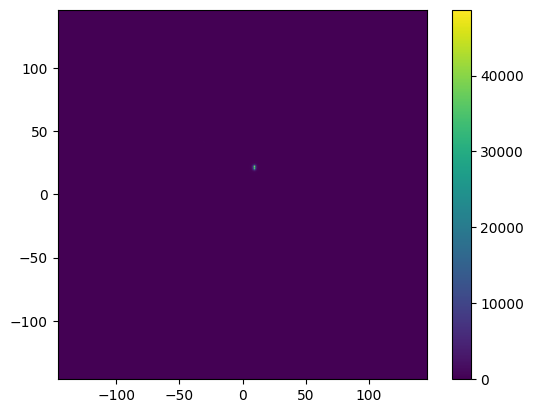

In [70]:
imshow_field(step[0])
plt.colorbar()

In [71]:
for img in step: #the dark subtraction isn't working so i had to median subtract the image... should I do this onsky?
       img -= np.median(img)

In [72]:
#system params
wavelength = 614E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle,snr_threshold=2.5,speckle_window=70) 

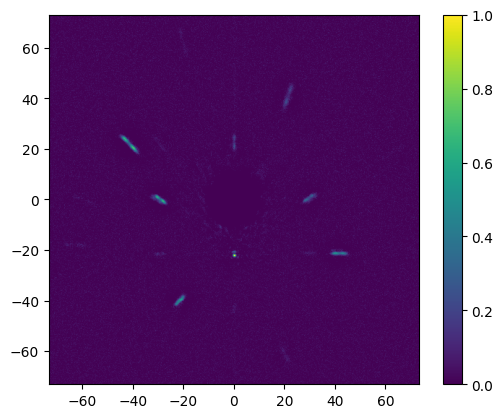

In [73]:
img = step[0]
hp = ADC.hpf(img,10)
img = ADC.crop_image(hp,extent=512,mask_diam=20)
#img = ADC.crop_image(img,extent=512,mask_diam=20)

imshow_field(img)
plt.colorbar()


In [80]:
q = ADC.slice_speckle_angle(img,0,print_updates=True,speckle_filter=True)

ADC.hp_sigma = 8
ADC.lp_sigma = 4

r = ADC.all_speckle_angles(img,speckle_filter=False)
s = ADC.all_speckle_angles(img,speckle_filter=True)
print(r)
print(s)

slope: 0.52
corresponding angle: 0.48 (rad) or 27.27°
[ 43.42250608 -35.13791169  18.67447104 -10.19648387]
[ 27.2740156  -32.60030846  16.73473323  -8.21448764]


/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


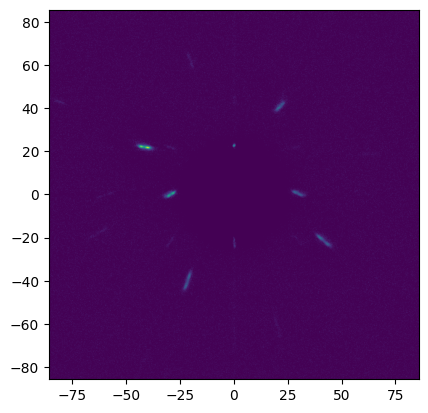

In [75]:
#filter all the image cubes from each step
diffs13_list = [] #list of speckle pair differences for each step
diffs24_list = [] 
speckle_list = [] #speckle angle list at each step

for i, field in enumerate(step):
    img = ADC.hpf(field,30)
    img = ADC.crop_image(img,mask_diam=20,extent=600)
    #filtered = ADC.crop_image(ADC.filter_image(field),extent=500,mask_diam=60) 
    imshow_field(img)
    a = ADC.all_speckle_angles(img,speckle_filter=True)
    speckle_list.append(a)
    diffs13_list.append(a[0] - a[2])
    diffs24_list.append(a[1] - a[3])

diffs13_list = np.array(diffs13_list)
diffs24_list = np.array(diffs24_list)

Slope of Speckles 1&3 Response: 1.9311167484402108
Offset of Speckles 1&3 Response: 0.007587325077099072
Slope of Speckles 2&4 Response: -5.675531641601287
Offset of Speckles 2&4 Response: 5.278125414413136


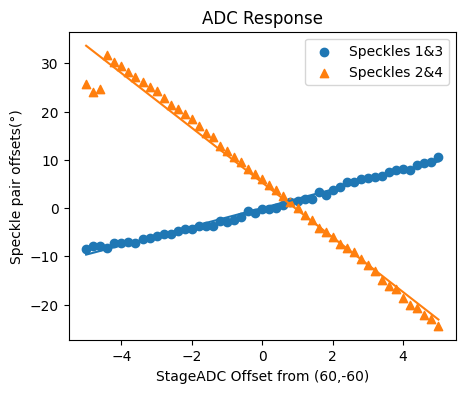

In [76]:
#plot the linear response
angle_offsets = np.linspace(-5,5,51) 

b1 = np.zeros(2)
m1 = np.zeros(2)

#only consider finite angles (clean up nan values)
idxs13 = np.isfinite(diffs13_list)
idxs24 = np.isfinite(diffs24_list)

h = [diffs13_list, diffs24_list]

avgs = [diffs13_list[idxs13], diffs24_list[idxs24]]
offsets = [angle_offsets[idxs13],angle_offsets[idxs24]]

labels = ['Speckles 1&3','Speckles 2&4']
markers = ['o','^','s','+']

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
for j in range(2):
    m1[j] , b1[j] = np.polyfit(offsets[j],avgs[j],deg=1)
    plt.scatter(offsets[j], avgs[j], label=labels[j],marker=markers[j])
    linepoints = b1[j] + m1[j] * offsets[j]
    plt.plot(offsets[j], linepoints)
    print(f'Slope of {labels[j]} Response: {m1[j]}')
    print(f'Offset of {labels[j]} Response: {b1[j]}')

#plt.scatter(0,0,color='Red')

plt.title('ADC Response')
plt.xlabel('StageADC Offset from (60,-60)')
plt.ylabel('Speckle pair offsets(°)')
plt.legend()
plt.show()

In [77]:
#finding the response/control matrices
response = np.matrix([m1])
ctrl_matrix = np.linalg.pinv(response)
#print(ctrl_matrix.T)

ctrl_matrix = ctrl_matrix.T
print(ctrl_matrix)

ADC.control_matrix = ctrl_matrix

[[ 0.05373038 -0.15791302]]


In [78]:
commands = []

for i in range(len(diffs13_list)):
    measurement = np.array([h[0][i],h[1][i]])
    if np.isfinite(measurement.all()):
        commands.append(-np.squeeze(ADC.calculate_command(measurement.T)))

commands = np.array(commands)
command_idxs = np.isfinite(commands)

slope: 1.0000000000000004
offset: -0.8330770706220787


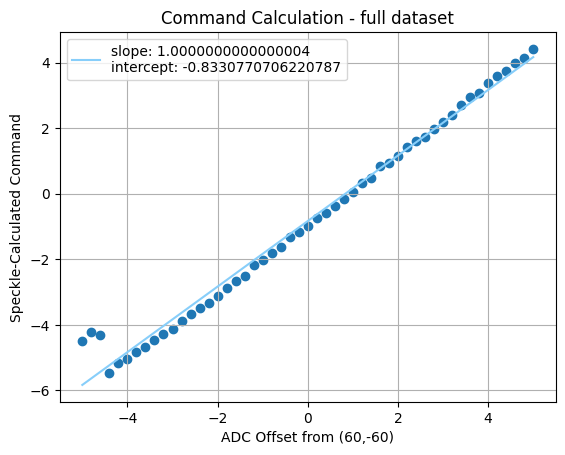

In [79]:
#plotting versus the actual angles:
m, b = np.polyfit(angle_offsets[command_idxs],commands[command_idxs],deg=1)

print(f'slope: {m}')
print(f'offset: {b}')

plt.scatter(angle_offsets[command_idxs],commands[command_idxs])
plt.plot(angle_offsets[command_idxs], m * angle_offsets[command_idxs] + b,color='lightskyblue',label=f'slope: {m}\nintercept: {b}')
plt.title('Command Calculation - full dataset')
plt.xlabel('ADC Offset from (60,-60)')
plt.ylabel('Speckle-Calculated Command')
plt.legend()
plt.grid()
plt.show()